# Case 1: The do-nothing matrix: did the 89 percent model find anyone?

*Applies chapters 1, 2 and 3: the confusion matrix, cell by cell; precision, recall and F1 derived; class imbalance against accuracy. Also searched as: confusion matrix sklearn, accuracy paradox, imbalanced classification.*

**Who needs the answer.** Kalpa Retail's Marketing team, who were told on Monday that the repeat-purchase classifier is about 90 percent accurate, and Anand Iyer in Finance, who prices every nudge at Rs 40 and every missed buyer at about Rs 1,200 of margin.

**The questions on the way.** How accurate is a model that calls nobody? How many buyers does Monday's model actually find at the default threshold of 0.5? Which single number would have exposed it on Monday?

The real data is a Portuguese bank's phone campaign (UCI Bank Marketing, 41,188 calls, May 2008 to November 2010): the bank called clients to sell a term deposit, which is the same decision as Kalpa's nudge. You will be able to read the bank's matrix aloud in Kalpa's words and say why its accuracy hides the empty column.

## Where does the data come from, and what state do we start in?

The cell below downloads the bank's file once into a cache in your home folder and reads the cached copy on every later run, so nothing is written into the repository. It then rebuilds Monday's state exactly: the same thirteen customer-table columns, the same seeded split (the test slice stays sealed until Friday) and the same logistic model. Everything today is scored on the 8,238 validation clients.

In [1]:
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "font.size": 12, "axes.titlesize": 13,
                     "axes.spines.top": False, "axes.spines.right": False})
INK, VIOLET, ROSE, GREEN, MUTED, LIGHT = "#1A0F5C", "#5B3FD6", "#D63A6A", "#1F8A5B", "#6B6690", "#EEEAFB"

# Load the day's public dataset once; later runs read the cached copy.
# UCI Bank Marketing, bank-additional-full.csv, CC BY 4.0 (Moro, Rita and Cortez, 2014).
import io, zipfile, pathlib, urllib.request
import numpy as np, pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

CACHE = pathlib.Path.home() / ".cache" / "c2_datasets"
CACHE.mkdir(parents=True, exist_ok=True)

def load_bank():
    f = CACHE / "bank-additional-full.csv"
    if not f.exists():
        url = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"
        outer = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(url, timeout=60).read()))
        inner = zipfile.ZipFile(io.BytesIO(outer.read("bank-additional.zip")))
        f.write_bytes(inner.read("bank-additional/bank-additional-full.csv"))
    return pd.read_csv(f, sep=";")

# The customer table on the morning of the call (Monday's columns): who the client is, how earlier campaigns went.
PROFILE = ["age", "job", "marital", "education", "default", "housing", "loan"]
HISTORY = ["contact", "month", "day_of_week", "campaign", "previous", "poutcome"]
COLS = PROFILE + HISTORY

def week_split(df, seed=42):
    """Test is sealed first (20 percent, Friday's envelope); the rest splits 75/25 into train and validation."""
    y = (df["y"] == "yes").astype(int)
    rest, test = train_test_split(df.index, test_size=0.20, stratify=y, random_state=seed)
    train, val = train_test_split(rest, test_size=0.25, stratify=y.loc[rest], random_state=seed)
    return df.loc[train], df.loc[val], df.loc[test]

def logistic(columns, df):
    # pandas 3 reads text as the "str" dtype, so test for numbers rather than for object.
    num = [c for c in columns if pd.api.types.is_numeric_dtype(df[c])]
    cat = [c for c in columns if c not in num]
    prep = ColumnTransformer([("num", StandardScaler(), num),
                              ("cat", OneHotEncoder(handle_unknown="ignore"), cat)])
    return Pipeline([("prep", prep), ("model", LogisticRegression(max_iter=2000))])

bank = load_bank()
train, val, test = week_split(bank)
model = logistic(COLS, bank).fit(train[COLS], (train["y"] == "yes").astype(int))
y_val = (val["y"] == "yes").astype(int).to_numpy()      # 1 = the client subscribed (a buyer)
p_val = model.predict_proba(val[COLS])[:, 1]             # the model's P(buy) for each validation client
print(f"rows {len(bank):,}; train {len(train):,}, validation {len(val):,}, test {len(test):,} (sealed until Friday)")
print(f"buyers in validation: {y_val.sum():,} of {len(y_val):,}, a base rate of {y_val.mean():.2%}")

rows 41,188; train 24,712, validation 8,238, test 8,238 (sealed until Friday)
buyers in validation: 928 of 8,238, a base rate of 11.26%


In [2]:
def cells(y, p, threshold):
    """The four boxes at one threshold: act (call, nudge) when the score is at or above it."""
    act = p >= threshold
    tp = int((act & (y == 1)).sum()); fp = int((act & (y == 0)).sum())
    fn = int((~act & (y == 1)).sum()); tn = int((~act & (y == 0)).sum())
    return tp, fp, fn, tn

print("PASS  the file has 41,188 rows" if len(bank) == 41188 else "CHECK the row count differs from 41,188")
print("PASS  the validation slice holds 8,238 clients" if len(val) == 8238 else "CHECK the split differs")
print("PASS  the base rate is about 11 percent" if 0.11 < y_val.mean() < 0.115 else "CHECK the base rate moved")

PASS  the file has 41,188 rows
PASS  the validation slice holds 8,238 clients
PASS  the base rate is about 11 percent


## How accurate is the model that calls nobody?

The cheapest possible "model" says no to every client: never call, never nudge. Before you run the next cell, commit to a number.

**Predict before you run.** On the validation slice, the call-nobody rule is right on what share of clients? (a) about 50 percent, (b) about 75 percent, (c) about 89 percent, (d) about 97 percent.

In [3]:
p_nobody = np.zeros(len(y_val))                 # a score of zero for everyone: nobody clears any threshold
tp, fp, fn, tn = cells(y_val, p_nobody, 0.5)
acc_nobody = (tp + tn) / len(y_val)
print("The call-nobody rule, in Kalpa's words")
print(f"  nudged and bought (TP):      {tp:>6,}")
print(f"  nudged, did not buy (FP):    {fp:>6,}")
print(f"  left alone, bought (FN):     {fn:>6,}   every one a missed buyer")
print(f"  left alone, did not buy (TN):{tn:>6,}")
print(f"accuracy {acc_nobody:.4f}  ({tp + tn:,} right of {len(y_val):,}); buyers found: {tp} of {tp + fn:,}")

The call-nobody rule, in Kalpa's words
  nudged and bought (TP):           0
  nudged, did not buy (FP):         0
  left alone, bought (FN):        928   every one a missed buyer
  left alone, did not buy (TN): 7,310
accuracy 0.8874  (7,310 right of 8,238); buyers found: 0 of 928


**What happened.** The answer is (c): the rule that does nothing is right on 88.74 percent of clients, because 7,310 of the 8,238 never buy. The whole "nudged" column of its matrix is empty. Accuracy rewards it for the clients nobody needed to reach, and it found none of the 928 buyers.

## How many buyers does Monday's model find at 0.5?

Monday's model gives every client a probability of buying. The default in `model.predict` turns that into a yes at 0.5 or above. The next cell scores the model at that threshold and reads all four boxes.

**Predict before you run.** Monday's model is about one point more accurate than doing nothing. Of the 928 buyers, how many does it find? (a) about 900, (b) about 600, (c) about 400, (d) about 175.

In [4]:
tp, fp, fn, tn = cells(y_val, p_val, 0.5)
acc = (tp + tn) / len(y_val)
precision = tp / (tp + fp); recall = tp / (tp + fn); f1 = 2 * precision * recall / (precision + recall)
print("Monday's model at the default threshold 0.5, in Kalpa's words")
print(f"  nudged and bought (TP):      {tp:>6,}")
print(f"  nudged, did not buy (FP):    {fp:>6,}")
print(f"  left alone, bought (FN):     {fn:>6,}")
print(f"  left alone, did not buy (TN):{tn:>6,}")
print(f"accuracy  {acc:.4f}  against {acc_nobody:.4f} for calling nobody")
print(f"precision {precision:.3f}  ({tp} of the {tp + fp} it would call bought)")
print(f"recall    {recall:.3f}  ({tp} of the {tp + fn} buyers found)")
print(f"F1        {f1:.3f}")

Monday's model at the default threshold 0.5, in Kalpa's words
  nudged and bought (TP):         174
  nudged, did not buy (FP):        94
  left alone, bought (FN):        754
  left alone, did not buy (TN): 7,216
accuracy  0.8971  against 0.8874 for calling nobody
precision 0.649  (174 of the 268 it would call bought)
recall    0.188  (174 of the 928 buyers found)
F1        0.291


**What happened.** The answer is (d). At 0.5 the model calls 268 clients and 174 of them buy, so precision is 0.649: its calls are good. It finds 174 of 928 buyers, so recall is 0.188: it misses more than four buyers in five. Accuracy moved from 0.8874 to 0.8971 and told you none of this.

## What do the two matrices look like side by side?

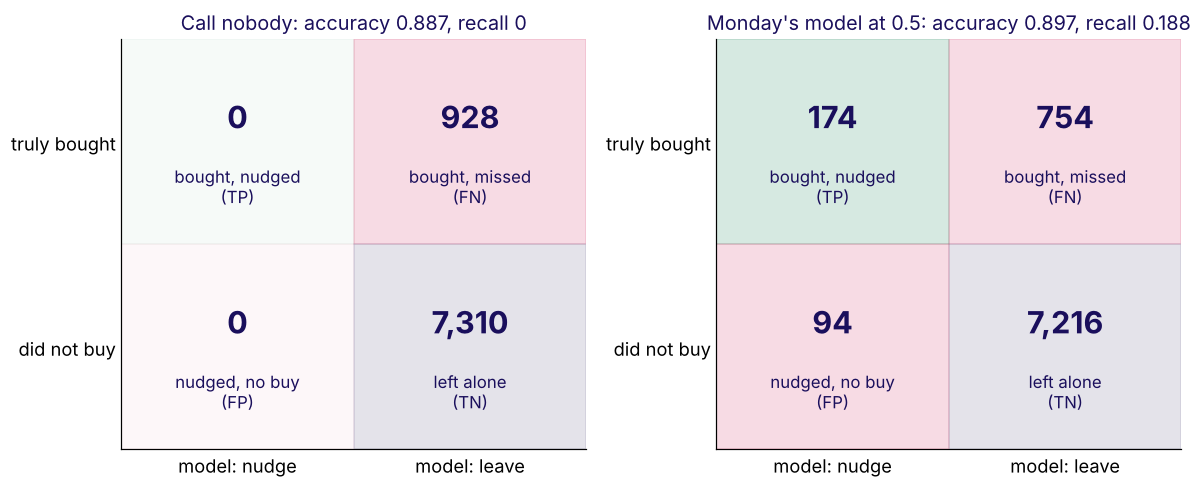

In [5]:
def draw_matrix(ax, tp, fp, fn, tn, title):
    grid = np.array([[tp, fn], [fp, tn]])
    colours = [[GREEN, ROSE], [ROSE, MUTED]]
    names = [["bought, nudged\n(TP)", "bought, missed\n(FN)"], ["nudged, no buy\n(FP)", "left alone\n(TN)"]]
    for i in range(2):
        for j in range(2):
            ax.add_patch(plt.Rectangle((j, 1 - i), 1, 1, color=colours[i][j], alpha=0.18 if grid[i, j] else 0.04))
            ax.text(j + 0.5, 1.62 - i, f"{grid[i, j]:,}", ha="center", va="center", fontsize=20, color=INK, weight="bold")
            ax.text(j + 0.5, 1.28 - i, names[i][j], ha="center", va="center", fontsize=11, color=INK)
    ax.set_xlim(0, 2); ax.set_ylim(0, 2); ax.set_xticks([0.5, 1.5]); ax.set_xticklabels(["model: nudge", "model: leave"])
    ax.set_yticks([1.5, 0.5]); ax.set_yticklabels(["truly bought", "did not buy"]); ax.set_title(title, color=INK)
    ax.tick_params(length=0)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
draw_matrix(axes[0], *cells(y_val, p_nobody, 0.5), "Call nobody: accuracy 0.887, recall 0")
draw_matrix(axes[1], *cells(y_val, p_val, 0.5), "Monday's model at 0.5: accuracy 0.897, recall 0.188")
plt.tight_layout(); plt.show()

## Where do the buyers sit on the score line?

The matrix is a cut through a picture: every client has a score, buyers and non-buyers form two humps, and the threshold is a vertical line. Everything right of the line is called.

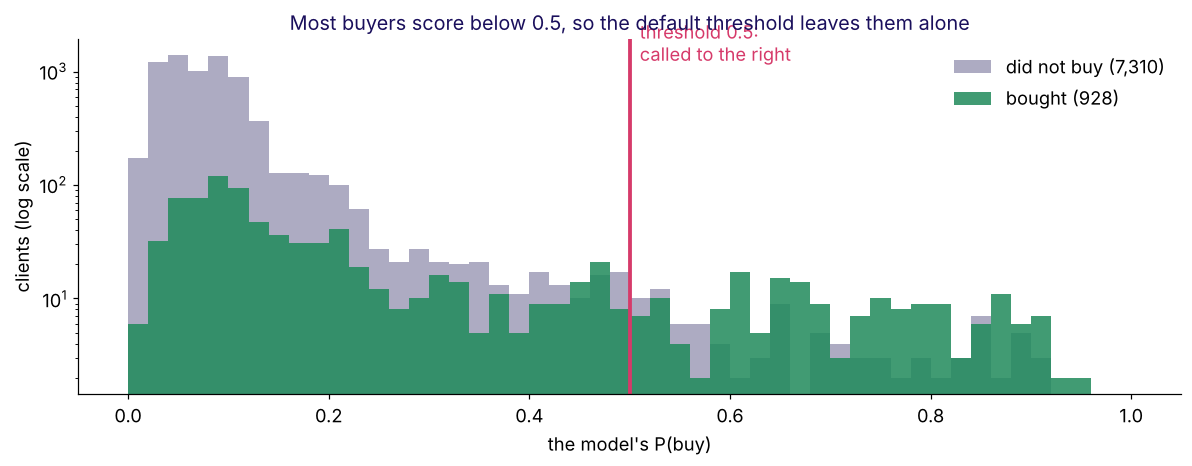

buyers scoring below 0.5: 754 of 928


In [6]:
fig, ax = plt.subplots(figsize=(11, 4.4))
bins = np.linspace(0, 1, 51)
ax.hist(p_val[y_val == 0], bins=bins, color=MUTED, alpha=0.55, label="did not buy (7,310)")
ax.hist(p_val[y_val == 1], bins=bins, color=GREEN, alpha=0.85, label="bought (928)")
ax.axvline(0.5, color=ROSE, lw=2.5); ax.text(0.51, ax.get_ylim()[1] * 0.85, "threshold 0.5:\ncalled to the right", color=ROSE)
ax.set_yscale("log"); ax.set_xlabel("the model's P(buy)"); ax.set_ylabel("clients (log scale)")
ax.set_title("Most buyers score below 0.5, so the default threshold leaves them alone", color=INK)
ax.legend(frameon=False); plt.tight_layout(); plt.show()
print(f"buyers scoring below 0.5: {(p_val[y_val == 1] < 0.5).sum()} of {(y_val == 1).sum()}")

## The trap: what goes wrong when the room reports "about 90 percent accurate"?

A hurried analyst writes to Marketing: **"The model is 89.7 percent accurate, so it is ready to pick whom to nudge."** That sentence is true and misleading. Marketing would fund a campaign believing the model finds buyers, when at 0.5 it would nudge 268 people and leave 754 of 928 buyers alone, about Rs 9.05 lakh of margin at Anand's Rs 1,200 each. The check that catches it is recall, read beside the do-nothing accuracy. The fix is to report the matrix and the recall with the accuracy, every time.

In [7]:
missed_margin = fn * 1200
print(f"buyers left alone at 0.5: {fn:,}, about Rs {missed_margin:,} of margin at Rs 1,200 each")
gain = acc - acc_nobody
print(f"accuracy gained over doing nothing: {gain * 100:.2f} points")
print("PASS  the do-nothing accuracy equals the share of non-buyers" if abs(acc_nobody - (1 - y_val.mean())) < 1e-12 else "CHECK do-nothing accuracy")
print("PASS  every buyer is either found or missed: TP + FN = 928" if tp + fn == y_val.sum() == 928 else "CHECK buyer count")
print("PASS  recall at 0.5 is below a quarter while accuracy is near 90 percent" if recall < 0.25 and acc > 0.89 else "CHECK recall")

buyers left alone at 0.5: 754, about Rs 904,800 of margin at Rs 1,200 each
accuracy gained over doing nothing: 0.97 points
PASS  the do-nothing accuracy equals the share of non-buyers
PASS  every buyer is either found or missed: TP + FN = 928
PASS  recall at 0.5 is below a quarter while accuracy is near 90 percent


## A second route: does scikit-learn's arithmetic agree with our count?

The four boxes were counted by hand above. `sklearn.metrics` computes the same ratios from the labels, and the two routes must agree to the last digit. Note the layout scikit-learn prints: rows are the truth, columns the prediction, and the top-left cell is the true negatives.

In [8]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score, accuracy_score
pred = (p_val >= 0.5).astype(int)
print(confusion_matrix(y_val, pred))            # [[TN, FP], [FN, TP]]
same = (np.isclose(precision_score(y_val, pred), precision) and np.isclose(recall_score(y_val, pred), recall)
        and np.isclose(accuracy_score(y_val, pred), acc))
print("PASS  scikit-learn agrees with the hand count" if same else "CHECK the two routes disagree")

[[7216   94]
 [ 754  174]]
PASS  scikit-learn agrees with the hand count


## What did this case establish, and what comes next?

| Question | Answer from this run |
|---|---|
| How accurate is calling nobody? | 0.8874, with 0 of 928 buyers found |
| How many buyers does the model find at 0.5? | 174 of 928, recall 0.188, precision 0.649 |
| Which number exposed it? | Recall, read beside the do-nothing accuracy |

**In the interview.** "Accuracy is 89 percent on an 11 percent outcome. Is the model good?" Ask for the true-positive cell first; on this file the do-nothing rule already scores 88.7 percent.

Case 2 asks what threshold Anand's costs call for, and whether the model earns its keep there.